In [1]:
import os

from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_core.messages import HumanMessage
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import MessagesState
from langgraph.prebuilt import ToolNode
from pypdf import PdfReader
from tavily import TavilyClient

In [2]:
load_dotenv()

True

In [3]:
model = "gpt-5.6-sol"

llm = ChatOpenAI(
    model=model,
    temperature=0.0,
    max_tokens=500,
    timeout=50,
    reasoning_effort="low",
    max_retries=2,
)

In [4]:
embeddings_fn = OpenAIEmbeddings(model="text-embedding-3-large")

In [5]:
vector_store = Chroma(
    collection_name="rag_demo",
    embedding_function=embeddings_fn,
    persist_directory="./chroma_langchain_db",
)

In [6]:
file_path = "data/exam_guide.pdf"

reader = PdfReader(file_path)

docs: list[Document] = []

for page in reader.pages:
    source = f"{file_path}"
    docs.append(Document(page_content=page.extract_text(), metadata={"source": source}))

print(f"Loaded {len(docs)} documentation pages.")

Loaded 3 documentation pages.


In [7]:
text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
all_splits = text_splitter.split_documents(docs)

print(f"Split documentation into {len(all_splits)} chunks.")

Split documentation into 8 chunks.


In [8]:
vector_store.add_documents(documents=all_splits)

print(f"Indexed {len(all_splits)} chunks.")

Indexed 8 chunks.


In [9]:
class State(MessagesState):
    question: str
    documents: list[Document]
    search_required: str
    answer: str

In [10]:
def retrieve(state: State):
    question = state["question"]
    retrieved_docs = vector_store.similarity_search(question, k=3)
    return {"documents": retrieved_docs}

In [11]:
def evaluator(state: State):
    question = state["question"]
    documents = state["documents"]
    docs_content = "\n\n".join(doc.page_content for doc in documents)

    template = ChatPromptTemplate(
        [
            ("system", "You are an assistant for evaluating context."),
            (
                "human",
                """Use the following pieces of retrieved context to determine if an 
                additional search is required. If the context is relevant to the 
                question, your response should be 'NO', i.e. no need for search. 
                If the context is not relevant, say 'YES', i.e. search the web for an answer. 
                Don't explain anything, if it's to search the web, say YES, otherwise, NO. 
                \n# Question: \n-> {question} 
                \n# Context: \n-> {context} 
                \n# Answer: """,
            ),
        ]
    )

    chain = template | llm | StrOutputParser()

    search_required = chain.invoke({"context": docs_content, "question": question})

    return {"search_required": search_required}

In [12]:
@tool
def web_search(question: str) -> dict:
    """
    Return top search results for a given search query
    """
    tavily_client = TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))
    response = tavily_client.search(question)
    return response

In [13]:
llm_with_tools = llm.bind_tools([web_search])

In [14]:
def researcher(state: State):
    question = state["question"]
    messages = state["messages"]
    if not messages:
        human_message = HumanMessage(
            "Conduct a web research to findout the answer to the following question: "
            f"```{question}```"
        )
        messages = [human_message]

    ai_message = llm_with_tools.invoke(messages)
    messages.append(ai_message)
    return {"messages": messages, "answer": ai_message.content}

In [15]:
def augment(state: State):
    question = state["question"]
    documents = state["documents"]
    docs_content = "\n\n".join(doc.page_content for doc in documents)

    template = ChatPromptTemplate(
        [
            ("system", "You are an assistant for question-answering tasks."),
            (
                "human",
                """Use the following pieces of retrieved context to answer the question. 
                If you don't know the answer, just say that you don't know. 
                Use three sentences maximum and keep the answer concise. 
                \n# Question: \n-> {question} 
                \n# Context: \n-> {context} 
                \n# Answer: """,
            ),
        ]
    )

    messages = template.invoke(
        {"context": docs_content, "question": question}
    ).to_messages()

    return {"messages": messages}

In [16]:
def generate(state: State):
    ai_message = llm.invoke(state["messages"])
    return {"answer": ai_message.content, "messages": ai_message}

In [17]:
def rag_router(state: State):
    search_required = state["search_required"]
    if search_required.lower() == "yes":
        return "researcher"

    return "augment"

In [18]:
def tool_router(state: State):
    last_message = state["messages"][-1]
    if last_message.tool_calls:
        return "web_search"

    return END

In [19]:
workflow = StateGraph(State)

workflow.add_node("retrieve", retrieve)
workflow.add_node("augment", augment)
workflow.add_node("generate", generate)
workflow.add_node("evaluator", evaluator)
workflow.add_node("researcher", researcher)
workflow.add_node("web_search", ToolNode([web_search]))

workflow.add_edge(START, "retrieve")
workflow.add_edge("retrieve", "evaluator")

workflow.add_conditional_edges(
    source="evaluator", path=rag_router, path_map=["augment", "researcher"]
)

workflow.add_conditional_edges(
    source="researcher", path=tool_router, path_map=["web_search", END]
)
workflow.add_edge("web_search", "researcher")

workflow.add_edge("augment", "generate")
workflow.add_edge("generate", END)

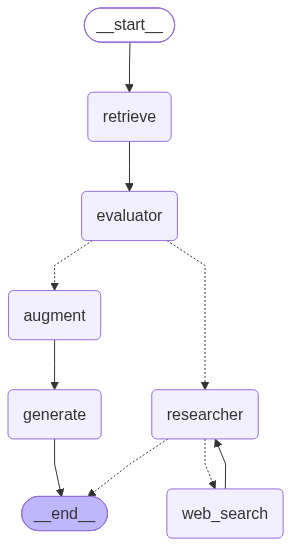

In [20]:
graph = workflow.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [21]:
output = graph.invoke(
    input={"question": "What is Pokemon?"},
)

In [22]:
output["answer"]

[{'type': 'text',
  'text': '## What is Pokémon?\n\n**Pokémon**—short for **“Pocket Monsters”**—is a Japanese entertainment franchise centered on fictional creatures called Pokémon. In its world, people known as **Pokémon Trainers** catch, collect, train, trade, and battle these creatures, each of which has distinctive abilities and characteristics.\n\nThe franchise began in Japan in **1996** with the Game Boy role-playing games *Pokémon Red* and *Pokémon Green*. The concept was created by Japanese game designer **Satoshi Tajiri**. The games’ basic formula involves exploring a fictional region, assembling a team of Pokémon, battling other trainers, and completing a catalog called the **Pokédex**.\n\nPokémon subsequently expanded into a broad multimedia franchise that includes:\n\n- Video games and mobile apps, including *Pokémon GO*\n- The Pokémon Trading Card Game\n- Animated television series and films\n- Manga, toys, clothing, and other merchandise\n\nThus, “Pokémon” can refer both 

In [23]:
for message in output["messages"]:
    message.pretty_print()

================================ Human Message =================================

Conduct a web research to findout the answer to the following question: ```What is Pokemon?```
================================== Ai Message ==================================

[{'id': 'rs_04291df8de079e1c006af48aa0804487d28db31753fe94e217', 'summary': [], 'type': 'reasoning', 'content': [], 'encrypted_content': 'gAAAAABq9IqixnS8XnWfI-ca-0YUx3wAj3WSZNnFs0S3fc_4EokaSCsMa-IocBljv-3ebw83sU2PIBg8rtxJBQZ4b2qkDDXmRO32bbRNKfwOJ9w-uHx139GB-NIxloMS83XX8tqsc93uwcE1o5KRud-lqPxNpqkT0LKfl9VahXORw3gFHlND_6167huTRXmDf34myXBFuFPaUb3qyG7mWHoS27hKXZEkVs0VrTbayIGEMQcfB48iUivxSszTqbkSLCYZ3dZ8Nmif7rm2mJWsHxMTvxXz_TuXspEBn-2X4AmYZlmJ8dqQ2N4AgTOgD4KnrS9D0u2i3Emnpc1QHYeM1txBOBBoGEWOzYVyWXcvjy9vtEfY7VRywJBss0ZTwOnbDyFWytt9DAUjXhtJJDdew2ToymUXMNdWB2xaBO9a7Pr0sqlfdLbM05lMrsqq7bdmBpQOV2R2_JtSnFHQ8E8YAWnkdE3uhXvdVmzI4o1zedhgU_ol6DQ00CM-zeEUJI3DZ6I0caMWHSfTyPYX7DIU2OAMga6z6g8Zln_BnleSVZT0eMsQRuQ2K0HK_5ItGRMz4s4j9SZMj-46UZ-35r2COafHmU4

In [24]:
output["search_required"]

'YES'

In [25]:
output = graph.invoke(
    input={"question": "What is The Langchain exam main requirement?"},
)

In [26]:
output["search_required"]

'NO'

In [27]:
for message in output["messages"]:
    message.pretty_print()

================================ System Message ================================

You are an assistant for question-answering tasks.
================================ Human Message =================================

Use the following pieces of retrieved context to answer the question. 
                If you don't know the answer, just say that you don't know. 
                Use three sentences maximum and keep the answer concise. 
                
# Question: 
-> What is The Langchain exam main requirement? 
                
# Context: 
-> CERTIFICATION · EXAM GUIDE
LangChain Certified Agent Engineer
Exam guide: format, rules, and what each section covers.
ARRIVE EARLY
Please join your exam session at least 15 minutes before your scheduled start time. This window is used for ID check, room scan, and
system veriﬁcation with your proctor.
If you join more than 10 minutes after your scheduled start time you will be marked as a no-show and will need to reschedule the
exam at full cost.
T